# Prueba Intertrimestral

**Nombre: Diego Luis**  
**Apellidos:de Mazarredo Martín**  

**Tiempo de la prueba:** 2 horas  
**Asignatura:** Desarrollo de Aplicaciones para la Visualización de Datos  
**Fecha:** 19 de octubre de 2027  

## Instrucciones

- Escribe **código limpio y autoexplicativo**.  
- Se pueden utilizar **los materiales de clase**.  
- Se puede utilizar **internet** para búsqueda de dudas y documentación.  
- **No se puede utilizar ningún tipo de LLM** (ChatGPT, Copilot, Gemini, etc.).  
- **No se puede utilizar mensajería instantánea**.  
- Al finalizar, **sube tu notebook a GitHub** y envía el enlace del fichero según las instrucciones del profesor.

**[Subé el enlace aquí](https://forms.cloud.microsoft/e/vSwHis0f1B)**

## Dataset “City Micromobility Hourly”

El fichero `city_micromobility_hourly.csv` contiene **alquileres horarios** de bicicletas y patinetes compartidos en una ciudad (ene 2025 – dic 2026): meteorología, tipo de día, usuarios ocasionales/abonados, duración media, ingresos y una etiqueta de alta demanda.

Hay un `.txt` con la descripción de las variables en la misma carpeta.


## Inicialización de librerías


In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, confusion_matrix

# Ejercicio 1 — Programación (2 puntos)

a) (0.6 pts) Crea una función `rental_fee(duration_min, bike_type, is_member)` que calcule la tarifa de un viaje en euros, redondeada a **dos decimales**, con estas reglas:

- Tarifa base: **1.00 €** si `bike_type == "classic"`, **1.50 €** si `bike_type == "electric"`.
- Coste por minuto: **0.05 €/min** (classic) o **0.08 €/min** (electric).
- Si `is_member` es `True`, aplica un **20 % de descuento** sobre el total.
- Si `bike_type` no es `"classic"` ni `"electric"`, lanza `ValueError`.

Ejemplo orientativo: `rental_fee(20, "classic", False)` → `2.00`.


In [109]:
def rental_fee(duration_min, bike_type, is_member):
    if bike_type == "classic":
        fee = 1.00 + 0.05 *duration_min
    elif bike_type == "electric":
        fee= 1.50 + 0.08*duration_min
    else: 
        raise ValueError("Escoge 'classic' or 'electric', lo que has introducido es incorrecto")
    if is_member:
        fee= fee * 0.8
    return fee

In [110]:
print(rental_fee(25,"classic",False))

2.25


b) (0.6 pts) Crea una función `demand_label(total_rentals, threshold)` que devuelva `"Alta"` si `total_rentals >= threshold`, `"Media"` si está entre `threshold/2` (incluido) y `threshold` (excluido), y `"Baja"` en caso contrario.


In [74]:
def demand_label(total_rentals, threshold):
    if total_rentals>= threshold:
        return "Alta"
    elif total_rentals>= threshold / 2:
        return "Media"
    else:
        return "Baja"
    print(demand_label(150, 100))
    print(demand_label(75, 100))
    print(demand_label(25, 100))

In [75]:
print(rental_fee(25, "classic", True)) 

1.8


c) (0.6 pts) Genera un DataFrame llamado `tripsDemo` con **al menos 10 filas** y columnas:

- `duration_min` (float)
- `bike_type` (`"classic"` o `"electric"`)
- `is_member` (bool)
- `fee` (calculada con `rental_fee`)
- `total_rentals` (int, inventado)
- `demand` (calculada con `demand_label`, usando por ejemplo `threshold=40`)

Muestra el DataFrame completo.


In [107]:
duration_min = [5.0, 12.5, 20.0,8.0, 30.0, 15.0,45.0, 10.0, 25.0, 18.0]
bike_type = ["classic", "electric", "classic", "electric", "classic", "electric", "classic", "classic", "electric", "electric"]
is_member= [False, True,False, False,True,False,True, False, True, True]
total_rentals =[21,55,40,60,27,16,80, 40, 34, 16]
fee = []
demand = []
for i in range(len(duration_min)):
    fee.append(rental_fee(duration_min[i],bike_type[i],is_member[i]))
    demand.append(demand_label(total_rentals[i],40))
tripsDemo= pd.DataFrame()
tripsDemo["duration_min"]= duration_min
tripsDemo["bike_type"]=bike_type
tripsDemo["fee"]=fee
tripsDemo["demand"]=demand
tripsDemo["is_member"]=is_member

In [108]:
print(tripsDemo)

   duration_min bike_type    fee demand  is_member
0           5.0   classic  1.250  Media      False
1          12.5  electric  2.000   Alta       True
2          20.0   classic  2.000   Alta      False
3           8.0  electric  2.140   Alta      False
4          30.0   classic  2.000  Media       True
5          15.0  electric  2.700   Baja      False
6          45.0   classic  2.600   Alta       True
7          10.0   classic  1.500   Alta      False
8          25.0  electric  2.800  Media       True
9          18.0  electric  2.352   Baja       True


d) (0.2 pts) Integra ambas funciones en una clase `MicromobilityTools` que, a partir de listas/arrays de `duration_min`, `bike_type` e `is_member`, calcule las tarifas y (opcionalmente) etiquete demanda a partir de una lista de `total_rentals` y un `threshold`.


In [ ]:
class MicromobilityTools():
    def __init__(self,duration_min,bike_type,is_member):
        self.duration_min =duration_min
        self.bike_type =bike_type
        self.is_member =is_member
    def fees(self):
        fees = []
        for i in range(len(self.duration_min)):
            fees.append(rental_fee(self.duration_min[i], self.bike_type[i], self.is_member[i]))
        return fees
    def demand(self,total_rentals,threshold):
        labels = []
        for j in range(len(total_rentals)):
            labels.append(demand_label(total_rentals[j],threshold))
        return labels
tools = MicromobilityTools(duration_min,bike_type,is_member)
print(tools.fees())
print(tools.demand(total_rentals, 40))


[1.25, 2.0, 2.0, 2.14, 2.0, 2.7, 2.6, 1.5, 2.8000000000000003, 2.352]
['Media', 'Alta', 'Alta', 'Alta', 'Media', 'Baja', 'Alta', 'Alta', 'Media', 'Baja']


## Ejercicio 2 — Exploración y visualización (3 puntos)

a) (0.75 pts) Carga `city_micromobility_hourly.csv` en un DataFrame `mobilityData`. Muestra las 5 primeras filas y el número de filas y columnas.


In [78]:
mobilityData = pd.read_csv("city_micromobility_hourly.csv")
print(mobilityData.shape)
mobilityData.head()

(17520, 23)


,datetime,year,month,day,hour,weekday,season,is_holiday,is_weekend,is_workingday,...,wind_kmh,precip_mm,casual_users,member_users,total_rentals,avg_trip_min,avg_distance_km,electric_share,revenue_eur,high_demand
0,2025-01-01 00:00:00,2025,1,1,0,2,Winter,1,0,0,...,9.7,0.0,2,8,10,23.3,4.94,0.391,10.83,0
1,2025-01-01 01:00:00,2025,1,1,1,2,Winter,1,0,0,...,2.8,0.0,1,5,6,17.3,3.92,0.327,5.35,0
2,2025-01-01 02:00:00,2025,1,1,2,2,Winter,1,0,0,...,9.0,0.0,1,4,5,17.3,4.24,0.405,4.77,0
3,2025-01-01 03:00:00,2025,1,1,3,2,Winter,1,0,0,...,5.4,0.0,2,10,12,17.3,3.98,0.408,10.88,0
4,2025-01-01 04:00:00,2025,1,1,4,2,Winter,1,0,0,...,2.4,0.0,1,4,5,21.6,5.90,0.336,5.16,0


b) (0.75 pts) Crea una función `describeData(dataFrame)` que, para cada columna, devuelva: tipo de dato, número de nulos y porcentaje de nulos.


In [79]:
def describeData(dataFrame):
    columnas = []
    tipos = []
    nulos = []
    porcentaje = []
    for col in dataFrame.columns:
        columnas.append(col)
        tipos.append(dataFrame[col].dtypes)
        nulos.append(dataFrame[col].isna().sum())
        porcentaje.append(round(dataFrame[col].isna().sum() / len(dataFrame) * 100, 2))
    resumen = pd.DataFrame()
    resumen["columna"] = columnas
    resumen["tipo"] = tipos
    resumen["nulos"] = nulos
    resumen["porcentaje_nulos"] = porcentaje
    return resumen

c) (0.75 pts) Usa `describeData(mobilityData)` y comenta brevemente (2–3 líneas) qué variables tienen más valores faltantes y qué harías con ellas antes de modelar.


In [80]:
describeData(mobilityData)

,columna,tipo,nulos,porcentaje_nulos
0,datetime,str,0,0.00
1,year,int64,0,0.00
2,month,int64,0,0.00
3,day,int64,0,0.00
4,hour,int64,0,0.00
5,weekday,int64,0,0.00
6,season,str,0,0.00
7,is_holiday,int64,0,0.00
8,is_weekend,int64,0,0.00
9,is_workingday,int64,0,0.00


d) (0.75 pts) Elabora **dos** visualizaciones:

1. Un gráfico de correlación entre variables numéricas relevantes (por ejemplo `temp_c`, `humidity`, `wind_kmh`, `precip_mm`, `casual_users`, `member_users`, `total_rentals`, `revenue_eur`).
2. Un gráfico que muestre la demanda media (`total_rentals`) por `hour` (y, si quieres, separando fin de semana / laborable).

Comenta 2–3 hallazgos (correlaciones, horas punta, efecto del clima, etc.).


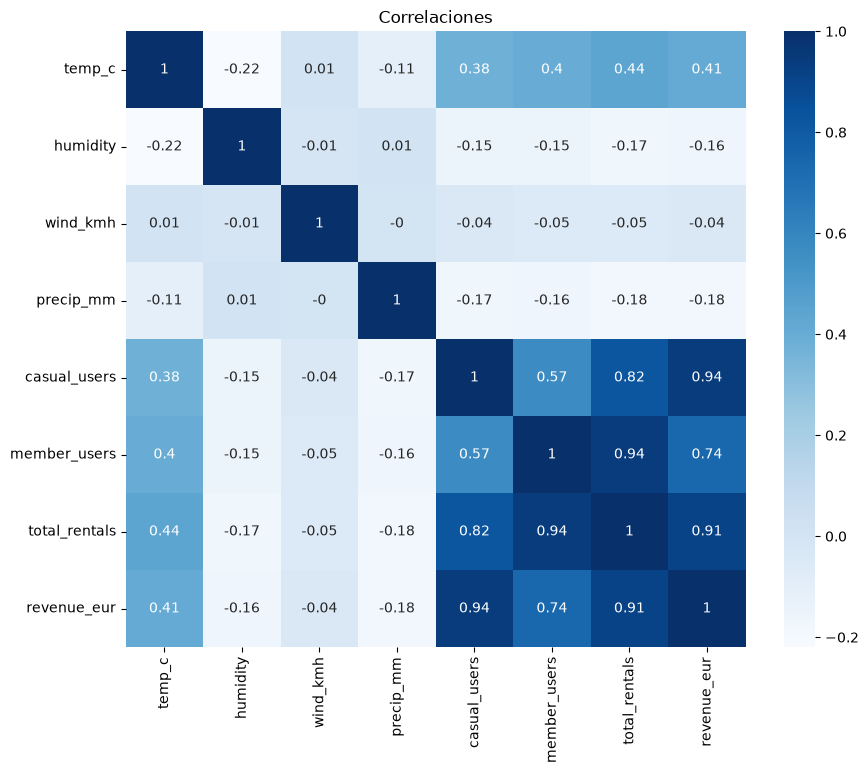

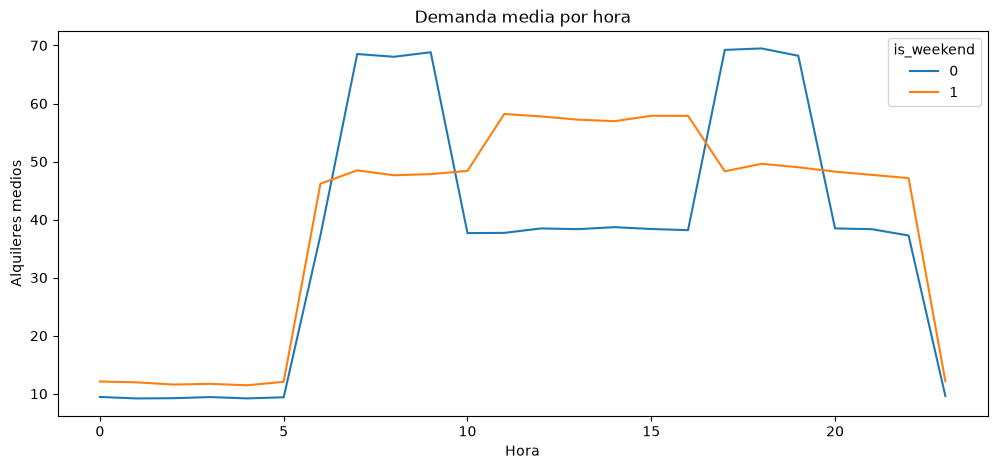

In [111]:
variables = ["temp_c", "humidity", "wind_kmh", "precip_mm", "casual_users", "member_users", "total_rentals", "revenue_eur"]
ok = mobilityData["humidity"].notna() & mobilityData["wind_kmh"].notna()
datosCorr = mobilityData.loc[ok].copy()

matriz = []
for var1 in variables:
    fila = []
    for var2 in variables:
        corr, _ = pearsonr(datosCorr[var1], datosCorr[var2])
        fila.append(round(corr, 2))
    matriz.append(fila)

plt.figure(figsize=(10, 8))
sns.heatmap(matriz, annot=True, cmap="Blues", xticklabels=variables, yticklabels=variables)
plt.title("Correlaciones")
plt.show()

grouped = mobilityData.groupby(["hour", "is_weekend"], as_index=False)["total_rentals"].mean()
plt.figure(figsize=(12, 5))
sns.lineplot(data=grouped, x="hour", y="total_rentals", hue="is_weekend")
plt.xlabel("Hora")
plt.ylabel("Alquileres medios")
plt.title("Demanda media por hora")
plt.show()

La demanda se guía mucho por dos tramos de horas durante la semana, entre las 5 y las 10 donde se incrementa la demanda llegando a un pico en 70, y entre las 16 aproximadamente y las 20 donde genera el efecto opuesto y simétrico. Esto nos da información muy valiosa, especialmente fijandonos en que no sigue la misma regla que el fin de semana donde observamos una evolución que se estabiliza mucho más en un valor que se podría parecer más a la media de entre semana entre las 5 y las 20. Solo que al ser fin de semana aguanta más hasta media noche.

Podemos observar que las condiciones de temperatura tienen una correlación bastante considereable con los rentals de unos 0.44. Mientras que otros factores que darían lugar a pensar que afectaban también no lo hacen, como precipitaciones, viento o humedad, llegando a tener valores negativos, lo cual es sorprendente, ya que no solo no está correlado sino que es contrario.

## Ejercicio 3 — Regresión (2 puntos)

Queremos predecir `total_rentals`.

a) (0.25 pts) Define `targetVar = "total_rentals"` y selecciona **3–5** variables predictoras numéricas razonables (p. ej. `hour`, `temp_c`, `humidity`, `wind_kmh`, `precip_mm`, `is_workingday`, `is_weekend`). Construye `X` e `y`, tratando nulos de forma simple (p. ej. eliminar filas o imputar la mediana).


In [105]:
targetVar ="total_rentals"
predictor_vars =["hour","temp_c","humidity","wind_kmh","is_workingday"]
ok =mobilityData["humidity"].notna() & mobilityData["wind_kmh"].notna()
df =mobilityData.loc[ok].copy()

X =df[predictor_vars]
y =df[targetVar]
print(targetVar)
print(predictor_vars)

total_rentals
['hour', 'temp_c', 'humidity', 'wind_kmh', 'is_workingday']


b) (0.25 pts) Divide en entrenamiento (70 %) y prueba (30 %) con `random_state=42`.


In [84]:
X_train,X_test,y_train,y_test = train_test_split(X, y, test_size = 0.3, random_state = 42)

c) (0.75 pts) Entrena un `LinearRegression`, calcula **R²** y **MSE** en el conjunto de prueba y comenta el resultado en 1–2 líneas.


In [85]:
regr = LinearRegression().fit(X_train, y_train)

y_pred = regr.predict(X_test)

print(mean_squared_error(y_test, y_pred))
print(r2_score(y_test, y_pred))

424.1605437245436
0.281777813172841


d) (0.75 pts) Entrena un `RandomForestRegressor` (mismo split) y compara R² y MSE con la regresión lineal. ¿Cuál funciona mejor y por qué crees que es así?


In [86]:
rf = RandomForestRegressor(random_state = 42).fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

print(mean_squared_error(y_test, y_pred_rf))
print(r2_score(y_test, y_pred_rf))

94.5322534965035
0.8399305101889669


Si realizamos una comparación de rendimiento fijándonos tanto en el MSE como en R2 podemos observar que random forest tiene un error mucho menor que la regresión lineal además de que el R2 es casi tres veces mayor en RandomForest. Así viendo que explica mucho mejor y predice las variables mayor rendimiento.

## Ejercicio 4 — Clasificación (2 puntos)

Usa la columna `high_demand` (1 = demanda alta, 0 = no).

a) (0.25 pts) Comprueba el balance de clases (`value_counts` o proporción) de `high_demand`.


In [90]:
print(mobilityData["high_demand"].value_counts())
print(mobilityData["high_demand"].value_counts(normalize = True))

high_demand
0    12071
1     5449
Name: count, dtype: int64
high_demand
0    0.688984
1    0.311016
Name: proportion, dtype: float64


In [96]:
print(mobilityData["weather"].value_counts())

weather
Clear      14664
Drizzle     1763
Cloudy       782
Rain         311
Name: count, dtype: int64


b) (0.75 pts) Entrena un `LogisticRegression` para predecir `high_demand` usando variables de contexto (hora, clima, tipo de día, etc.). Recuerda preparar `X`/`y` y el split train/test.


In [97]:
mobilityData["weather_num"] = mobilityData["weather"].map({"Clear": 0, "Cloudy": 1, "Drizzle": 2, "Rain": 3})
variablesClf = ["hour","temp_c","humidity","wind_kmh","precip_mm","weather_num","is_workingday"]

ok = mobilityData["humidity"].notna() & mobilityData["wind_kmh"].notna()
df = mobilityData.loc[ok].copy()

X = df[variablesClf]
y = df["high_demand"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42)

clf_log = LogisticRegression(max_iter=10000, tol=0.1)
clf_log.fit(X_train, y_train)

,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.1
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",10000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

c) (0.25 pts) Calcula la **accuracy** y muestra la **matriz de confusión**.


In [102]:
predictions = clf_log.predict(X_test)

print(clf_log.score(X_test, y_test))

print(confusion_matrix(y_test, predictions))

0.7278554778554779
[[3154  378]
 [1023  593]]


d) (0.75 pts) Interpreta qué factores parecen asociarse más a la alta demanda (coeficientes del modelo logístico y/o importancia si usas un árbol; o argumentación basada en tus gráficos del ejercicio 2).


In [104]:
for i in range(len(variablesClf)): print(variablesClf[i],round(clf_log.coef_[0][i], 3))

hour 0.038
temp_c 0.074
humidity -0.034
wind_kmh -0.068
precip_mm -0.013
weather_num -0.031
is_workingday -0.016


## Ejercicio 5 — Conclusión (1 punto)

En un máximo de **300 palabras**, resume:

* Qué factores (hora, clima, tipo de día, etc.) parecen mover más la demanda de micromovilidad.  
* Qué modelo predictivo te ha funcionado mejor y por qué.  
* Qué mejorarías con más tiempo o datos (más ciudades, eventos, precio dinámico, etc.).


Al finalizar:

**[Subé el enlace aquí](https://forms.cloud.microsoft/e/vSwHis0f1B)**



Podemos observar que las condiciones de temperatura tienen una correlación bastante considereable con los rentals de unos 0.44. Mientras que otros factores que darían lugar a pensar que afectaban también no lo hacen, como precipitaciones, viento o humedad, llegando a tener valores negativos, lo cual es sorprendente, ya que no solo no está correlado sino que es contrario.
Si realizamos una comparación de rendimiento fijándonos tanto en el MSE como en R2 podemos observar que random forest tiene un error mucho menor que la regresión lineal además de que el R2 es casi tres veces mayor en RandomForest. Así viendo que explica mucho mejor y predice las variables mayor rendimiento.
Con más tiempo añadiría más variables que pudiesen explicar la variabilidad del rent, como variables estacionales o de tendencia que ayuden a explicar mejor la demanda. Además de hacer un tratamiendo más exhaustivo de las variables de entrada para poder mejorar la precisión del modelo y la explicabilidad de estas variables junto con las nuevas. 